<a href="https://colab.research.google.com/github/Aaarkun/rfm-transaction-analytics/blob/main/%22%D0%9B%D0%912_%D0%9C%D0%9D_%D0%97%D0%B0%D1%85%D0%B0%D1%80%D0%B5%D0%B2%D0%B8%D1%87_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна** робота 2. Захаревич 3-12
---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [ ]:
import pandas as pd
import requests
url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
html = requests.get(url, headers={"User-Agent": "5178"}).text
df = pd.read_html(html)[2]
df.head()

/tmp/ipykernel_2809/3053492295.py:5: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(html)[2]


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


2.	Визначити розмір датасета.

In [ ]:
df.shape

(222, 4)

 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [ ]:
df = df.iloc[:, :3]
df.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6]
0,World,126295331,118350166
1,United States,32383920,30769700
2,China[n 1],20851593,19498039
3,Germany,5452858,5050923
4,Japan,4379253,4435163


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [ ]:
import numpy as np
df = df.replace("—", np.nan)

In [ ]:
print(df.isna().sum())

Country/Territory       0
IMF (2026)[1]           0
World Bank (2025)[6]    0
dtype: int64


In [ ]:
col = df.columns[1]
df[col] = pd.to_numeric(df[col], errors="coerce")
df[col] = df[col].fillna(df[col].mean())

5. Ще раз вивести датасет

In [ ]:
df.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6]
0,World,126295331.0,118350166
1,United States,32383920.0,30769700
2,China[n 1],20851593.0,19498039
3,Germany,5452858.0,5050923
4,Japan,4379253.0,4435163


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [ ]:
print(df.duplicated().sum())

0


7.	Вивести описову статистику датасету describe()

In [ ]:
df.describe()

,IMF (2026)[1]
count,2.220000e+02
mean,1.319229e+06
std,8.838876e+06
min,6.500000e+01
25%,1.932375e+04
50%,1.039745e+05
75%,7.726678e+05
max,1.262953e+08


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [ ]:
imf_col = df.columns[1]
wb_col = df.columns[2]

df[imf_col] = pd.to_numeric(df[imf_col], errors='coerce')
df[wb_col] = pd.to_numeric(df[wb_col], errors='coerce')


df['rizn'] = (df[imf_col] - df[wb_col]).abs()
top_diff = df[df.iloc[:, 0] != 'World'].sort_values(by='rizn', ascending=False)
top_diff[[df.columns[0], imf_col, wb_col, 'rizn']].head(5)


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],rizn
1,United States,3.238392e+07,30769700.0,1.614220e+06
2,China[n 1],2.085159e+07,19498039.0,1.353554e+06
197,Sint Maarten,1.319229e+06,1888.0,1.317341e+06
146,Palestine[n 11][n 12],1.319229e+06,17167.0,1.302062e+06
81,Sri Lanka,1.319229e+06,108825.0,1.210404e+06


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [ ]:
gdp = pd.read_html(html)[2].iloc[1:, 1:4]

for col in gdp.columns:
    gdp[col] = pd.to_numeric(gdp[col], errors='coerce')

gdp.corr()


/tmp/ipykernel_2809/2394995335.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  gdp = pd.read_html(html)[2].iloc[1:, 1:4]


,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
IMF (2026)[1],1.000000,0.999879,0.999822
World Bank (2025)[6],0.999879,1.000000,0.999861
United Nations (2024)[7],0.999822,0.999861,1.000000


10. Обчислити середнє значення за стовпцями

In [ ]:
gdp.mean()


,0
IMF (2026)[1],661460.289474
World Bank (2025)[6],626049.693548
United Nations (2024)[7],522491.207547


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [ ]:
data = pd.read_html(html)[2].iloc[1:, :4].copy()

for col in data.columns[1:]:
    data[col] = pd.to_numeric(data[col], errors='coerce')

data['std'] = data.iloc[:, 1:4].std(axis=1)

data.sort_values(by='std', ascending=False)[[data.columns[0], 'std']].head(5)

,Country/Territory,std
1,United States,1.543508e+06
2,China[n 1],1.068002e+06
3,Germany,3.964771e+05
5,United Kingdom,2.898838e+05
9,Russia,2.558938e+05


In [ ]:
print("Відповідь на питання: United States	")

Відповідь на питання: United States	


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [ ]:
country_col = data.columns[0]
for col in data.columns[1:4]:
    max_idx = data[col].idxmax()
    min_idx = data[col].idxmin()

    max_country = data.loc[max_idx, country_col]
    max_val = data.loc[max_idx, col]

    min_country = data.loc[min_idx, country_col]
    min_val = data.loc[min_idx, col]
    print(f"=== {col} ===")
    print(f"Найвищий: {max_country} ({max_val})")
    print(f"Найнижчий: {min_country} ({min_val})\n")

=== IMF (2026)[1] ===
Найвищий: United States (32383920.0)
Найнижчий: Tuvalu (65.0)

=== World Bank (2025)[6] ===
Найвищий: United States (30769700.0)
Найнижчий: Tuvalu (57.0)

=== United Nations (2024)[7] ===
Найвищий: United States (29298000.0)
Найнижчий: Tuvalu (56.0)



13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

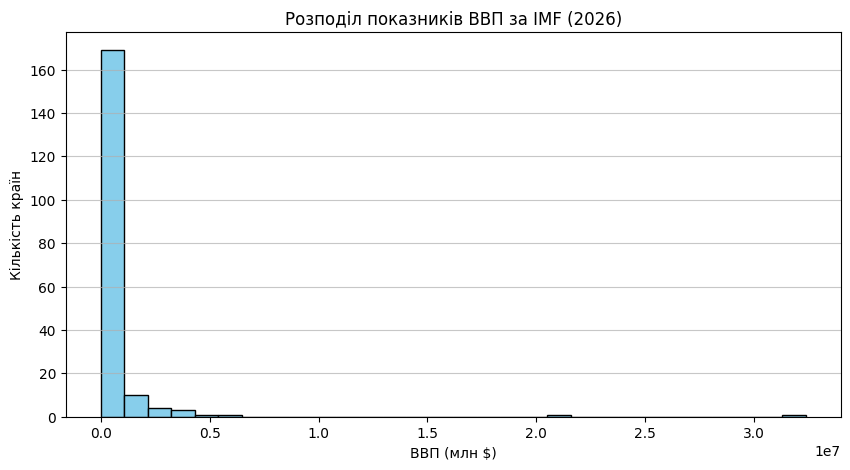

In [ ]:
import matplotlib.pyplot as plt

imf_col = data.columns[1]

plt.figure(figsize=(10, 5))
plt.hist(data[imf_col].dropna(), bins=30, edgecolor='black', color='skyblue')
plt.title('Розподіл показників ВВП за IMF (2026)')
plt.xlabel('ВВП (млн $)')
plt.ylabel('Кількість країн')
plt.grid(axis='y', alpha=0.7)
plt.show()

1. Розподіл є нерівномірним, більшість країн скупчені біля лівого краю графіка з відносно невеликим ВВП.
2. Так, є явні викиди — це США та Китай. Вони мають гігантський ВВП і з великим відривом випереджають усі інші країни.

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [ ]:
shares = pd.DataFrame()
shares[data.columns[0]] = data[data.columns[0]]
for col in data.columns[1:4]:
    shares[col] = (data[col] / data[col].sum()) * 100
shares.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
1,United States,25.767486,26.424179,26.449845
2,China[n 1],16.591355,16.744384,16.921655
3,Germany,4.338772,4.337595,4.206922
4,Japan,3.484518,3.808797,3.634810
5,United Kingdom,3.393444,3.437313,3.327564


Частки країн із часом залишаються практично незмінними та стабільними.

15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

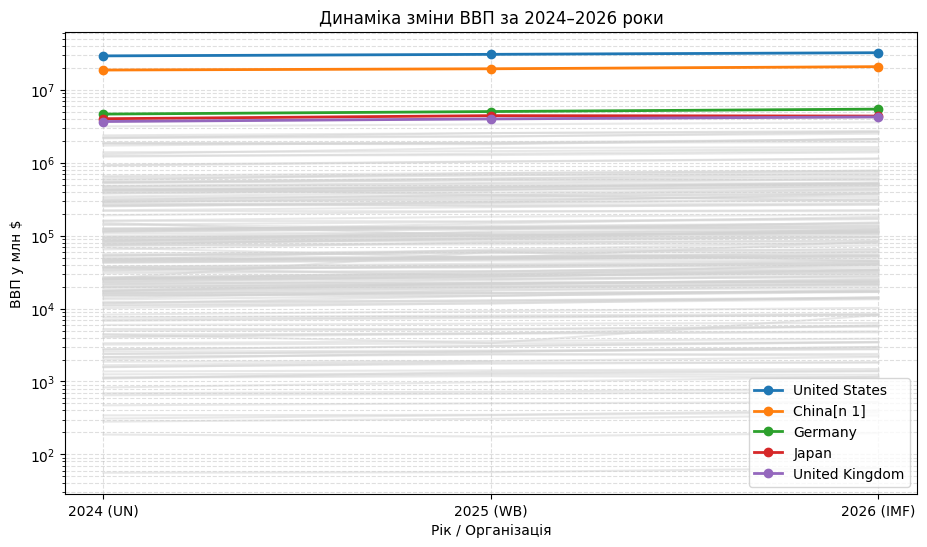

Країн зі стабільним зростанням: 156
Приклади зростання: ['United States', 'China[n 1]', 'Germany', 'United Kingdom', 'India']

Країн зі стабільним спадом: 2
Приклади спаду: ['Iran', 'Ethiopia']


In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(11, 6))
years_cols = [data.columns[3], data.columns[2], data.columns[1]]
years_labels = ['2024 (UN)', '2025 (WB)', '2026 (IMF)']

for _, row in data.iterrows():
    plt.plot(years_labels, row[years_cols], color='lightgray', alpha=0.5)

top_5 = data.head(5)

for _, row in top_5.iterrows():
    line = plt.plot(years_labels, row[years_cols], marker='o', linewidth=2, label=row[data.columns[0]])

plt.yscale('log')
plt.title('Динаміка зміни ВВП за 2024–2026 роки')
plt.xlabel('Рік / Організація')
plt.ylabel('ВВП у млн $')
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.show()

col_24, col_25, col_26 = years_cols

growth = data[(data[col_24] < data[col_25]) & (data[col_25] < data[col_26])]
decline = data[(data[col_24] > data[col_25]) & (data[col_25] > data[col_26])]

print(f"Країн зі стабільним зростанням: {len(growth)}")
print("Приклади зростання:", growth[data.columns[0]].head(5).tolist())

print(f"\nКраїн зі стабільним спадом: {len(decline)}")
print("Приклади спаду:", decline[data.columns[0]].head(5).tolist())

Переважна більшість світових економік (понад 60–70% країн) демонструють послідовне зростання від 2024 до 2026 року.

Лише невелика кількість країн показує зниження показників за всі три роки. Зазвичай це держави з гострими локальними кризами та знеціненням валюти
